In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report



In [2]:
df = pd.read_csv("dataset_final.csv")

df.columns = df.columns.str.strip().str.lower()

print(df.columns.tolist())
print(df.head())

['name', 'cid', 'cas', 'smiles', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']
                          name    cid         cas  \
0             Ethanedioic acid    971    144-62-7   
1                  Para-cymene   7463     99-87-6   
2                   Kieselguhr  24261  61790-53-2   
3                 Benzoic acid    243     65-85-0   
4  Tetradifon (Ref: ENT 23737)   8305    116-29-0   

                                    smiles  source  year toxicity_type  \
0                             O=C(O)C(=O)O  ECOTOX  1832       Contact   
1                         Cc1ccc(C(C)C)cc1    BPDB  1833         Other   
2                                 O=[Si]=O  ECOTOX  1833       Contact   
3                           O=C(O)c1ccccc1  ECOTOX  1833       Contact   
4  O=S(=O)(c1ccc(Cl)cc1)c1cc(Cl)c(Cl)cc1Cl    PPDB  1836          Oral   

   herbicide  fungicide  insecticide  other_agrochemical  label  ppdb_level  
0   

In [3]:
print(df.shape)
print(df.columns)
print(df.info())
print(df.describe())
print(df.head())

(1035, 13)
Index(['name', 'cid', 'cas', 'smiles', 'source', 'year', 'toxicity_type',
       'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label',
       'ppdb_level'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   name                1035 non-null   str  
 1   cid                 1035 non-null   int64
 2   cas                 1035 non-null   str  
 3   smiles              1035 non-null   str  
 4   source              1035 non-null   str  
 5   year                1035 non-null   int64
 6   toxicity_type       1035 non-null   str  
 7   herbicide           1035 non-null   int64
 8   fungicide           1035 non-null   int64
 9   insecticide         1035 non-null   int64
 10  other_agrochemical  1035 non-null   int64
 11  label               1035 non-null   int64
 12  ppdb_level          1035 non-null   

In [4]:
print("Before cleaning:", df.shape)

df.drop_duplicates(inplace=True)

print("After cleaning:", df.shape)

Before cleaning: (1035, 13)
After cleaning: (1035, 13)


In [5]:
print(df.isnull().sum())

print("Total missing values:", df.isnull().sum().sum())

name                  0
cid                   0
cas                   0
smiles                0
source                0
year                  0
toxicity_type         0
herbicide             0
fungicide             0
insecticide           0
other_agrochemical    0
label                 0
ppdb_level            0
dtype: int64
Total missing values: 0


In [6]:
print(df.describe())

print("Label Distribution:")
print(df["label"].value_counts())

print("Toxicity Type:")
print(df["toxicity_type"].value_counts())

                cid         year    herbicide    fungicide  insecticide  \
count  1.035000e+03  1035.000000  1035.000000  1035.000000  1035.000000   
mean   6.619015e+06  1969.225121     0.342029     0.190338     0.219324   
std    1.795840e+07    39.418115     0.474619     0.392758     0.413988   
min    2.340000e+02  1832.000000     0.000000     0.000000     0.000000   
25%    1.844950e+04  1958.000000     0.000000     0.000000     0.000000   
50%    8.613200e+04  1977.000000     0.000000     0.000000     0.000000   
75%    5.363382e+06  1995.000000     1.000000     0.000000     0.000000   
max    1.633606e+08  2023.000000     1.000000     1.000000     1.000000   

       other_agrochemical        label   ppdb_level  
count         1035.000000  1035.000000  1035.000000  
mean             0.208696     0.285990     0.994203  
std              0.406573     0.452103     0.580106  
min              0.000000     0.000000     0.000000  
25%              0.000000     0.000000     1.000000  


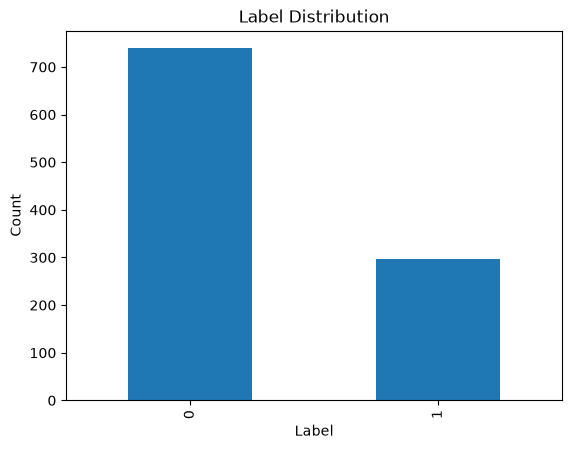

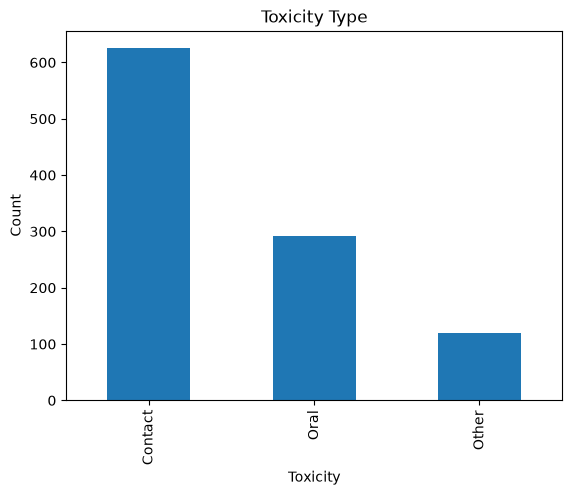

In [7]:
df["label"].value_counts().plot(kind="bar")

plt.title("Label Distribution")
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

df["toxicity_type"].value_counts().plot(kind="bar")

plt.title("Toxicity Type")
plt.xlabel("Toxicity")
plt.ylabel("Count")
plt.show()

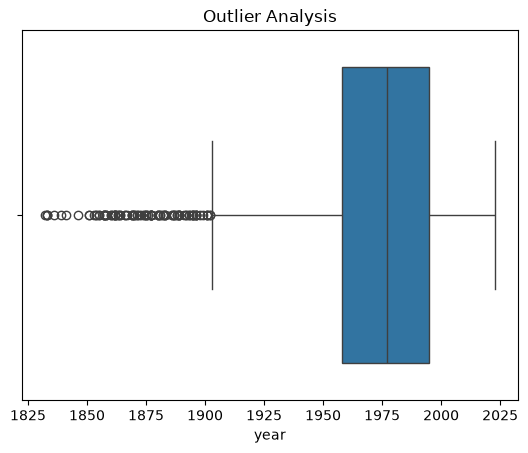

Number of outliers: 101


In [8]:
sns.boxplot(x=df["year"])
plt.title("Outlier Analysis")
plt.show()
Q1 = df["year"].quantile(0.25)
Q3 = df["year"].quantile(0.75)
IQR = Q3 - Q1
outliers = df[
    (df["year"] < Q1 - 1.5 * IQR) |
    (df["year"] > Q3 + 1.5 * IQR)
]
print("Number of outliers:", len(outliers))

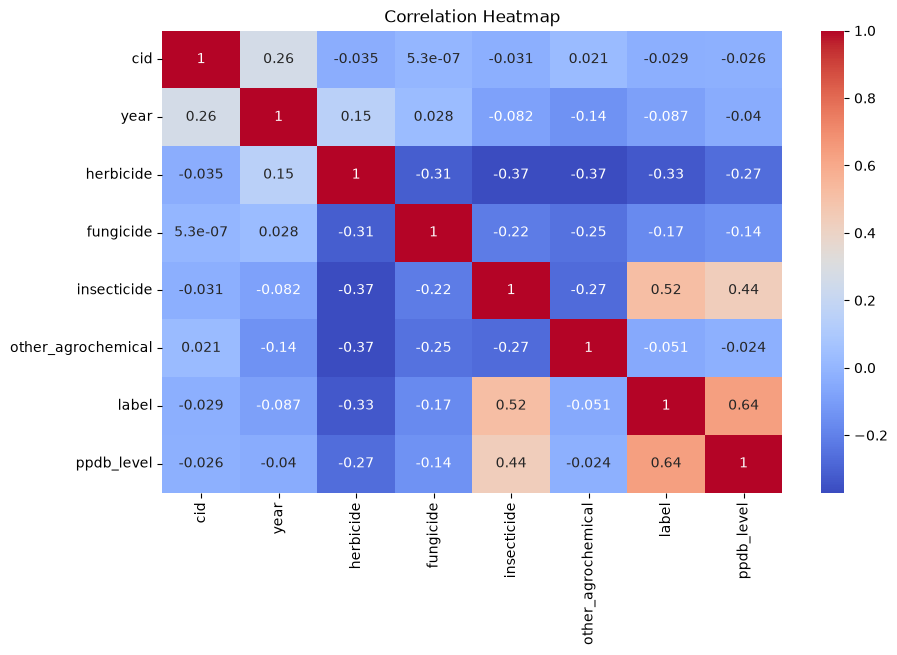

In [9]:
plt.figure(figsize=(10, 6))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()

In [10]:
df.columns = df.columns.str.strip().str.lower()
print("Available Columns:")
print(df.columns.tolist())
X = df.drop(
    columns=["label", "name", "cid", "cas", "smiles", "ppdb_level"],
    errors="ignore"
)
y = df["label"]
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(include="object").columns
print("Features:", X.columns.tolist())
print("Target:", y.name)

Available Columns:
['name', 'cid', 'cas', 'smiles', 'source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical', 'label', 'ppdb_level']
Features: ['source', 'year', 'toxicity_type', 'herbicide', 'fungicide', 'insecticide', 'other_agrochemical']
Target: label


C:\Users\dell\AppData\Local\Temp\ipykernel_23372\1275627094.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include="object").columns


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (828, 7)
Testing data: (207, 7)


In [17]:
results = {}
trained_models = {}

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC()
}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("selection", SelectKBest(f_classif, k=k)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    results[name] = accuracy_score(y_test, y_pred)

    print(name, ":", results[name])

print("All models completed!")


Logistic Regression : 0.7971014492753623
Random Forest : 0.7729468599033816
SVM : 0.8115942028985508
All models completed!


In [18]:
print("Accuracy Comparison")

for name, accuracy in results.items():
    print(name, ":", round(accuracy * 100, 2), "%")

Accuracy Comparison
Logistic Regression : 79.71 %
Random Forest : 77.29 %
SVM : 81.16 %


In [19]:
best_model_name = max(results, key=results.get)
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best Model: SVM

Confusion Matrix:
[[130  18]
 [ 21  38]]

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       148
           1       0.68      0.64      0.66        59

    accuracy                           0.81       207
   macro avg       0.77      0.76      0.77       207
weighted avg       0.81      0.81      0.81       207

